# Numerical PDE Homework 1

### Problem 1: Solving Stokes

In [133]:
import numpy as np
import scipy.linalg as la

import scipy.sparse as sp
import scipy.sparse.linalg as spla

import matplotlib as mpl
import matplotlib.pyplot as plt

import seaborn as sns
import seaborn.objects as so

PI = np.pi

# This setting makes it prints numerical outputs as, e.g. 3.14 and not np.float64(3.14)
# See https://numpy.org/doc/stable/reference/generated/numpy.set_printoptions.html
np.set_printoptions(legacy='1.25')

In [134]:
# # Setup
x_start , x_end = 0.0 , 1.0
y_start , y_end = 0.0 , 1.0
mu = 1.0
Nx = 100
Ny = Nx

dx = ( x_end - x_start ) / Nx
dy = ( y_end - y_start ) / Ny

# # GRIDS - arrays of actual x and y values
# unknowns are ordered k = i + j* Nx (x varies fastest )

# p at cell centers
x_P = x_start + ( np.arange ( Nx ) + 0.5) * dx
y_P = y_start + ( np.arange ( Ny ) + 0.5) * dy

# u on east / west faces ( x = x_end is the same face as x = x_start )
x_U = x_start + np.arange ( Nx ) * dx
y_U = y_P

# v on north / south faces
x_V = x_P
y_V = y_start + np.arange (Ny+1) * dy # We know top and bottom values but I found it easier to write Laplacian including these.

# Note the number of unknowns depends on boundary conditions !
nU = len(x_U) * len(y_U) #### # number of u unknowns here is Nx*Ny
nV = len(x_V) * len(y_V) #### # number of v unknowns here is Nx*(Ny+1) although some are known values
nP = len(x_P) * len(y_P) #### # number of p unknowns here is Nx*Ny


In [135]:
# Build the matrices in pieces

# U Laplacian

u_main_diag = -4 * np.ones(nU) # most common main diag value
u_main_diag[:Nx] -= 1
u_main_diag[-Nx:] -= 1 # This row and above come from BC U=0 at top and bottom of domain

u_super = np.ones(nU - 1)
u_sub = u_super.copy()

u_low = np.ones(nU - Ny)
u_high = np.ones(nU - Nx)

u_cols = np.concat((np.arange(Nx,nU), np.arange(1,nU), np.arange(nU), np.arange(nU-1), np.arange(nU-Ny)))
u_rows = np.concat((np.arange(nU-Nx), np.arange(nU-1), np.arange(nU), np.arange(1,nU), np.arange(Ny,nU)))
u_vals = np.concat((u_high, u_super, u_main_diag, u_sub, u_low))

for idx in range(len(u_vals)):
    if u_rows[idx] % Nx == 0 and u_cols[idx] == u_rows[idx] - 1:   # Periodic condition on left boundary
        u_cols[idx] += Nx
    elif u_rows[idx] % Nx == Nx-1 and u_cols[idx] == u_rows[idx] + 1:   # Periodic condition on right boundary
        u_cols[idx] -= Nx

# Add first and last row periodic terms by hand
u_vals = np.append(u_vals, [1,1])
u_cols = np.append(u_cols, [Nx-1, nU-Nx])
u_rows = np.append(u_rows, [0, nU-1])

Lu = sp.coo_matrix(( u_vals , ( u_rows , u_cols )) , shape =(nU , nU))

# V Laplacian

v_main_diag = -4 * np.ones(nV) # most common main diag value
v_main_diag[:Nx] = 1
v_main_diag[-Nx:] = 1 # Correspond to top and bottom of domain; implements Dirichelet conditions

v_super = np.ones(nV - 2*Nx)
v_sub = v_super.copy()

v_low = np.ones(nV - 2*Nx)
v_high = v_low.copy()

v_cols = np.concat((np.arange(nV-2*Nx), np.arange(Nx-1,nV-Nx-1), np.arange(nV), np.arange(Nx+1, nV-Nx+1), np.arange(2*Nx, nV)))
v_rows = np.concat((np.arange(Nx,nV-Nx), np.arange(Nx,nV-Nx), np.arange(nV), np.arange(Nx,nV-Nx), np.arange(Nx,nV-Nx)))
v_vals = np.concat((v_high, v_super, v_main_diag, v_sub, v_low))

for idx in range(len(v_vals)):
    if v_rows[idx] % Nx == 0 and v_cols[idx] == v_rows[idx] - 1:   # Periodic condition on left boundary
        v_cols[idx] += Nx
    elif v_rows[idx] % Nx == Nx-1 and v_cols[idx] == v_rows[idx] + 1:   # Periodic condition on right boundary
        v_cols[idx] -= Nx

Lv = sp.coo_matrix(( v_vals , ( v_rows , v_cols )) , shape =(nV , nV))

# First derivatives of P
# Multiply by h = dx = dy since h^2 is multiplied over to right side from Laplacian components

gx_main = np.ones(nU) * dx
gx_sub = np.zeros(nU-1) - dx
gx_vals = np.concat((gx_main, gx_sub))
gx_rows = np.concat((np.arange(nU), np.arange(1,nU)))
gx_cols = np.concat((np.arange(nU), np.arange(nU-1)))

# Periodicity shuffle
for idx in range(len(gx_vals)):
    if gx_rows[idx] % Nx == 0 and gx_cols[idx] == gx_rows[idx] -1:
        gx_cols[idx] += Nx

# Append one wraparound boundary term by hand
gx_vals = np.append(gx_vals, [-dx])
gx_rows = np.append(gx_rows, [0])
gx_cols = np.append(gx_cols, [Nx-1])

Gx = sp.coo_matrix((gx_vals, (gx_rows, gx_cols)), shape=(nU,nU))

gy_main = np.ones(nP-Nx) * dy
gy_low = np.zeros(nP-Nx) - dy
gy_vals = np.concat((gy_main, gy_low))
gy_rows = np.concat((np.arange(Nx, nP), np.arange(Nx, nP)))
gy_cols = np.concat((np.arange(Nx, nP), np.arange(nP-Nx)))

Gy = sp.coo_matrix((gy_vals, (gy_rows, gy_cols)), shape =(nV, nU))


# First derivatives of U and V
# Derivatives in middle of each cell so it falls on P grid
# Dy matrix is wider than Dx because of my funny choice to include V boundaries in my matrices

dx_super = np.ones(nP - 1)
dx_main = np.zeros(nP) - 1
dx_vals = np.concat((dx_super, dx_main))
dx_rows = np.concat((np.arange(nP-1), np.arange(nP)))
dx_cols = np.concat((np.arange(1,nP), np.arange(nP)))
for idx in range(len(dx_vals)):
    if dx_rows[idx] + 1 % Nx == 0 and dx_cols[idx] == dx_rows[idx] + 1:
        dx_cols[idx] -= Nx
# Add the last funny row by hand
dx_vals = np.append(dx_vals, 1)
dx_rows = np.append(dx_rows, nP-1)
dx_cols = np.append(dx_cols, nP-Nx)
Dx = sp.coo_matrix(( dx_vals , ( dx_rows , dx_cols )) , shape =(nP , nP))

dy_up = np.ones(nP)
dy_main = np.zeros(nP) - 1
dy_vals = np.concat((dy_up, dy_main))
dy_rows = np.concat((np.arange(nP), np.arange(nP)))
dy_cols = np.concat((np.arange(Nx, nP+Nx), np.arange(nP)))
Dy = sp.coo_matrix(( dy_vals , ( dy_rows , dy_cols )) , shape =(nP , nP + Nx))

#########
#
# BUILD THE BLOCK MATRIX !!
#
#########

A = sp.bmat ([[ mu * Lu , None , - Gx ],
[ None , mu * Lv , - Gy ],
[ Dx , Dy , None ]] , format = 'csr')

In [136]:
# Right hand sides

def f_eval(x,y):
    return (2*PI - 8*PI**2)*np.sin(2*PI*y)*np.sin(2*PI*x)

def g_eval(x,y):
    return (-2*PI-8*PI**2)*np.cos(2*PI*y)*np.cos(2*PI*x) + 4*PI*PI*np.cos(2*PI*x)

# Given k, find corresponding (i,j)
def unflatten(k):
    return (k%Nx, k//Nx)

# Find (x,y) on U grid
def u_grid(k):
    i,j = unflatten(k)
    return (i*dx, (j+0.5)*dy)

# Find (x,y) on V grid
def v_grid(k):
    i,j = unflatten(k)
    return ((i+0.5)*dx, j*dy)

# Find (x,y) on P grid
def p_grid(k):
    i,j = unflatten(k)
    return ((i+0.5)*dx, (j+0.5)*dy)

bu = f_eval(*u_grid(np.arange(nU)))*dx*dx

bv = g_eval(*v_grid(np.arange(nV)))*dy*dy
bv[:Nx] = -3.5
bv[nV-Nx:] = -3.5

bp = np.zeros(nP)

b = np . concatenate ([ bu , bv , bp ])




In [137]:
# solve
sol = spla . spsolve (A , b )

U = sol [: nU ]. reshape ( Ny , Nx )
V = sol [ nU : nU + nV ]. reshape ( Ny + 1, Nx )
P = sol [ nU + nV : nU + nV + nP ]. reshape (Ny , Nx )
P = P - np . mean (P)


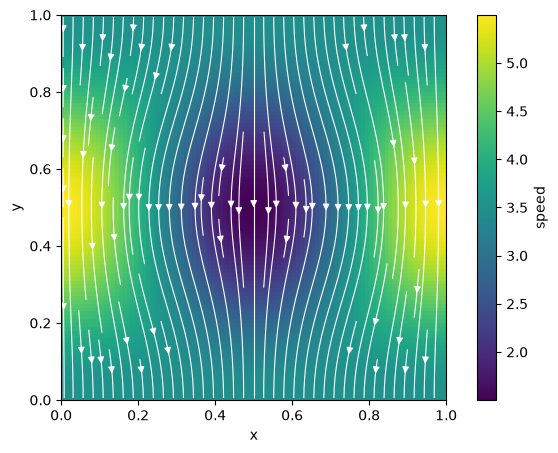

In [138]:
# PLOTTING
# This part (and none of the above cells) was done with AI assistance.

# To calculate magnitude, interpolate U and V grids to the center point of each cell

# V has Ny+1 rows, so this works for every cell
Vc = 0.5 * (V[:-1, :] + V[1:, :])                  # shape (Ny, Nx)

# Periodic in x: the right neighbor of the last column wraps to column 0
Uc = 0.5 * (U + np.roll(U, -1, axis=1))            # shape (Ny, Nx)

xc = (np.arange(Nx) + 0.5) * dx
yc = (np.arange(Ny) + 0.5) * dy
X, Y = np.meshgrid(xc, yc)                         # shape (Ny, Nx)

speed = np.hypot(Uc, Vc)

fig, ax = plt.subplots(figsize=(8, 5))

pcm = ax.pcolormesh(X, Y, speed, shading="auto", cmap="viridis")
fig.colorbar(pcm, ax=ax, label="speed")

# streamlines: show flow direction (needs 1D, evenly spaced xc and yc)
ax.streamplot(xc, yc, Uc, Vc, color="white", linewidth=0.8, density=1.3)

ax.set_aspect("equal")
ax.set_xlabel("x"); ax.set_ylabel("y")
plt.show()

fig.savefig("sol_plot.svg")
fig.savefig("sol_plot.pdf", bbox_inches="tight")

### Problem 2: Error Analysis

For this problem, define a function that outputs a solution for given number of gridpoints.

In [139]:
# LITERALLY COPY PASTE EVERYTHING SO WE CAN MAKE A FUNCTION THAT VARIES WITH N SO SORRY

def solution(n, num_choice):
    # # Setup
    x_start , x_end = 0.0 , 1.0
    y_start , y_end = 0.0 , 1.0
    mu = 1.0
    Nx = n
    Ny = Nx

    dx = ( x_end - x_start ) / Nx
    dy = ( y_end - y_start ) / Ny

    # # GRIDS - arrays of actual x and y values
    # unknowns are ordered k = i + j* Nx (x varies fastest )

    # p at cell centers
    x_P = x_start + ( np.arange ( Nx ) + 0.5) * dx
    y_P = y_start + ( np.arange ( Ny ) + 0.5) * dy

    # u on east / west faces ( x = x_end is the same face as x = x_start )
    x_U = x_start + np.arange ( Nx ) * dx
    y_U = y_P

    # v on north / south faces
    x_V = x_P
    y_V = y_start + np.arange (Ny+1) * dy # We know top and bottom values but I found it easier to write Laplacian including these.

    # Note the number of unknowns depends on boundary conditions !
    nU = len(x_U) * len(y_U) #### # number of u unknowns here is Nx*Ny
    nV = len(x_V) * len(y_V) #### # number of v unknowns here is Nx*(Ny+1) although some are known values
    nP = len(x_P) * len(y_P) #### # number of p unknowns here is Nx*Ny

    # Build the matrices in pieces

    # U Laplacian

    u_main_diag = -4 * np.ones(nU) # most common main diag value
    u_main_diag[:Nx] -= 1
    u_main_diag[-Nx:] -= 1 # This row and above come from BC U=0 at top and bottom of domain

    u_super = np.ones(nU - 1)
    u_sub = u_super.copy()

    u_low = np.ones(nU - Ny)
    u_high = np.ones(nU - Nx)

    u_cols = np.concat((np.arange(Nx,nU), np.arange(1,nU), np.arange(nU), np.arange(nU-1), np.arange(nU-Ny)))
    u_rows = np.concat((np.arange(nU-Nx), np.arange(nU-1), np.arange(nU), np.arange(1,nU), np.arange(Ny,nU)))
    u_vals = np.concat((u_high, u_super, u_main_diag, u_sub, u_low))

    for idx in range(len(u_vals)):
        if u_rows[idx] % Nx == 0 and u_cols[idx] == u_rows[idx] - 1:   # Periodic condition on left boundary
            u_cols[idx] += Nx
        elif u_rows[idx] % Nx == Nx-1 and u_cols[idx] == u_rows[idx] + 1:   # Periodic condition on right boundary
            u_cols[idx] -= Nx

    # Add first and last row periodic terms by hand
    u_vals = np.append(u_vals, [1,1])
    u_cols = np.append(u_cols, [Nx-1, nU-Nx])
    u_rows = np.append(u_rows, [0, nU-1])

    Lu = sp.coo_matrix(( u_vals , ( u_rows , u_cols )) , shape =(nU , nU))

    # V Laplacian

    v_main_diag = -4 * np.ones(nV) # most common main diag value
    v_main_diag[:Nx] = 1
    v_main_diag[-Nx:] = 1 # Correspond to top and bottom of domain; implements Dirichelet conditions

    v_super = np.ones(nV - 2*Nx)
    v_sub = v_super.copy()

    v_low = np.ones(nV - 2*Nx)
    v_high = v_low.copy()

    v_cols = np.concat((np.arange(nV-2*Nx), np.arange(Nx-1,nV-Nx-1), np.arange(nV), np.arange(Nx+1, nV-Nx+1), np.arange(2*Nx, nV)))
    v_rows = np.concat((np.arange(Nx,nV-Nx), np.arange(Nx,nV-Nx), np.arange(nV), np.arange(Nx,nV-Nx), np.arange(Nx,nV-Nx)))
    v_vals = np.concat((v_high, v_super, v_main_diag, v_sub, v_low))

    for idx in range(len(v_vals)):
        if v_rows[idx] % Nx == 0 and v_cols[idx] == v_rows[idx] - 1:   # Periodic condition on left boundary
            v_cols[idx] += Nx
        elif v_rows[idx] % Nx == Nx-1 and v_cols[idx] == v_rows[idx] + 1:   # Periodic condition on right boundary
            v_cols[idx] -= Nx

    Lv = sp.coo_matrix(( v_vals , ( v_rows , v_cols )) , shape =(nV , nV))

    # First derivatives of P
    # Multiply by h = dx = dy since h^2 is multiplied over to right side from Laplacian components

    gx_main = np.ones(nU) * dx
    gx_sub = np.zeros(nU-1) - dx
    gx_vals = np.concat((gx_main, gx_sub))
    gx_rows = np.concat((np.arange(nU), np.arange(1,nU)))
    gx_cols = np.concat((np.arange(nU), np.arange(nU-1)))

    # Periodicity shuffle
    for idx in range(len(gx_vals)):
        if gx_rows[idx] % Nx == 0 and gx_cols[idx] == gx_rows[idx] -1:
            gx_cols[idx] += Nx

    # Append one wraparound boundary term by hand
    gx_vals = np.append(gx_vals, -dx)
    gx_rows = np.append(gx_rows, 0)
    gx_cols = np.append(gx_cols, Nx-1)

    Gx = sp.coo_matrix((gx_vals, (gx_rows, gx_cols)), shape=(nU,nU))

    gy_main = np.ones(nP-Nx) * dy
    gy_low = np.zeros(nP-Nx) - dy
    gy_vals = np.concat((gy_main, gy_low))
    gy_rows = np.concat((np.arange(Nx, nP), np.arange(Nx, nP)))
    gy_cols = np.concat((np.arange(Nx, nP), np.arange(nP-Nx)))

    Gy = sp.coo_matrix((gy_vals, (gy_rows, gy_cols)), shape =(nV, nU))


    # First derivatives of U and V
    # Derivatives in middle of each cell so it falls on P grid
    # Dy matrix is wider than Dx because of my funny choice to include V boundaries in my matrices

    dx_super = np.ones(nP - 1)
    dx_main = np.zeros(nP) - 1
    dx_vals = np.concat((dx_super, dx_main))
    dx_rows = np.concat((np.arange(nP-1), np.arange(nP)))
    dx_cols = np.concat((np.arange(1,nP), np.arange(nP)))
    for idx in range(len(dx_vals)):
        if dx_rows[idx] + 1 % Nx == 0 and dx_cols[idx] == dx_rows[idx] + 1:
            dx_cols[idx] -= Nx
    # Add the last funny row by hand
    dx_vals = np.append(dx_vals, 1)
    dx_rows = np.append(dx_rows, nP-1)
    dx_cols = np.append(dx_cols, nP-Nx)
    Dx = sp.coo_matrix(( dx_vals , ( dx_rows , dx_cols )) , shape =(nP , nP))

    dy_up = np.ones(nP)
    dy_main = np.zeros(nP) - 1
    dy_vals = np.concat((dy_up, dy_main))
    dy_rows = np.concat((np.arange(nP), np.arange(nP)))
    dy_cols = np.concat((np.arange(Nx, nP+Nx), np.arange(nP)))
    Dy = sp.coo_matrix(( dy_vals , ( dy_rows , dy_cols )) , shape =(nP , nP + Nx))

    #########
    #
    # BUILD THE BLOCK MATRIX !!
    #
    #########

    A = sp.bmat ([[ mu * Lu , None , - Gx ],
    [ None , mu * Lv , - Gy ],
    [ Dx , Dy , None ]] , format = 'csr')

    # Right hand sides

    def f_eval(x,y):
        return (2*PI - 8*PI**2)*np.sin(2*PI*y)*np.sin(2*PI*x)

    def g_eval(x,y):
        return (-2*PI-8*PI**2)*np.cos(2*PI*y)*np.cos(2*PI*x) + 4*PI*PI*np.cos(2*PI*x)

    # Given k, find corresponding (i,j)
    def unflatten(k):
        return (k%Nx, k//Nx)

    # Find (x,y) on U grid
    def u_grid(k):
        i,j = unflatten(k)
        return (i*dx, (j+0.5)*dy)

    # Find (x,y) on V grid
    def v_grid(k):
        i,j = unflatten(k)
        return ((i+0.5)*dx, j*dy)

    # Find (x,y) on P grid
    def p_grid(k):
        i,j = unflatten(k)
        return ((i+0.5)*dx, (j+0.5)*dy)

    bu = f_eval(*u_grid(np.arange(nU)))*dx*dx

    bv = g_eval(*v_grid(np.arange(nV)))*dy*dy
    bv[:Nx] = -3.5
    bv[nV-Nx:] = -3.5

    bp = np.zeros(nP)

    b = np . concatenate ([ bu , bv , bp ])

    sol = spla . spsolve (A , b )

    # One new part: 
    if num_choice == True:

        U = sol [: nU ]. reshape ( Ny , Nx )
        V = sol [ nU : nU + nV ]. reshape ( Ny + 1, Nx )
        P = sol [ nU + nV : nU + nV + nP ]. reshape (Ny , Nx )
        P = P - np . mean (P)

    else:
        # If num_choice is not True then this gives analytic solutions
        # Put inside here because the grid is defined in this function

        def u_eval(x,y):
            return np.sin(2*PI*y)*np.sin(2*PI*x)

        U = u_eval(*u_grid(np.arange(nU))). reshape ( Ny , Nx )

        def v_eval(x,y):
            return -3.5 + np.cos(2*PI*x)*( np.cos(2*PI*y) - 1 )

        V = v_eval(*v_grid(np.arange(nV))). reshape ( Ny + 1, Nx )

        def p_eval(x,y):
            return np.sin(2*PI*y)*np.cos(2*PI*x)

        P = p_eval(*p_grid(np.arange(nP))). reshape (Ny , Nx )
        P_num = sol [ nU + nV : nU + nV + nP ]. reshape (Ny , Nx )
        P = P - np . mean (P)

    return (U, V, P)



In [140]:
# Errors

def u_error(n):
    u_num = solution(n,True)[0]
    u_an = solution(n, False)[0]
    return la.norm(u_num - u_an) / la.norm(u_an)

def v_error(n):
    v_num = solution(n,True)[1]
    v_an = solution(n, False)[1]
    return la.norm(v_num - v_an) / la.norm(v_an)

def p_error(n):
    p_num = solution(n,True)[2]
    p_an = solution(n, False)[2]
    return la.norm(p_num - p_an) / la.norm(p_an)



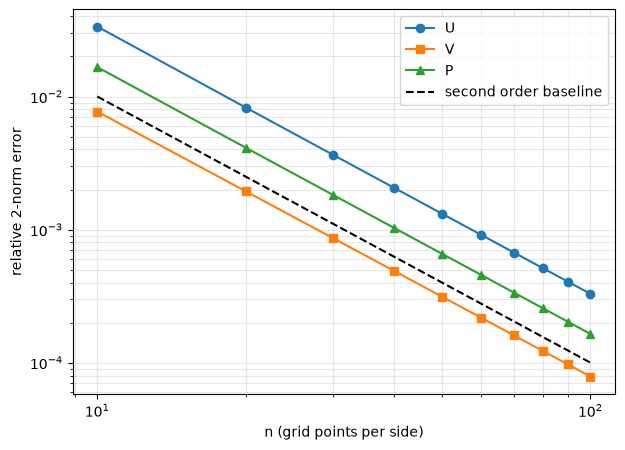

In [141]:
# Error plots
# As above, this cell is made with AI. All other cells (math as opposed to plotting) are made by me.


ns = np.arange(10, 101, 10)          # 10, 20, ..., 100

eu = [u_error(n) for n in ns]
ev = [v_error(n) for n in ns]
ep = [p_error(n) for n in ns]

fig, ax = plt.subplots(figsize=(7, 5))
ax.loglog(ns, eu, "o-", label="U")
ax.loglog(ns, ev, "s-", label="V")
ax.loglog(ns, ep, "^-", label="P")

ax.loglog(ns, 1/(ns*ns), "--", color="black", label="second order baseline") # Second order reference

ax.set_xlabel("n (grid points per side)")
ax.set_ylabel("relative 2-norm error")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.show()

fig.savefig("error_plot.pdf", bbox_inches="tight")

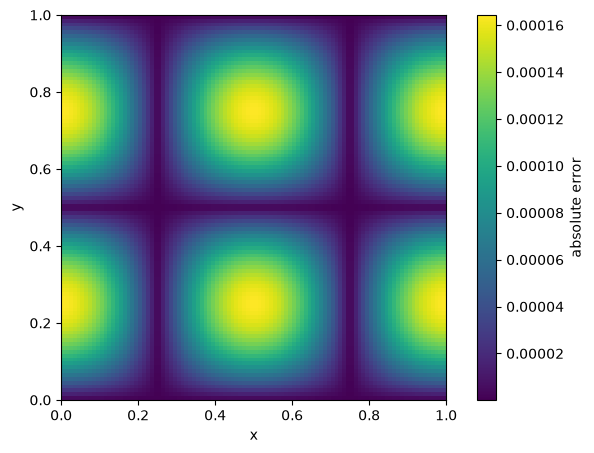

In [142]:
# Testing my wild function: does it still plot??

N = 100

# U = np.abs(solution(N, False)[0] - solution(N, True)[0])

# V = np.abs(solution(N, False)[1] - solution(N, True)[1])

P = np.abs(solution(N, False)[2] - solution(N, True)[2])

# To calculate magnitude, interpolate U and V grids to the center point of each cell

# V has Ny+1 rows, so this works for every cell
Vc = 0.5 * (V[:-1, :] + V[1:, :])                  # shape (Ny, Nx)

# Periodic in x: the right neighbor of the last column wraps to column 0
Uc = 0.5 * (U + np.roll(U, -1, axis=1))            # shape (Ny, Nx)

xc = (np.arange(N) + 0.5) / N
yc = (np.arange(N) + 0.5) / N
X, Y = np.meshgrid(xc, yc)                         # shape (Ny, Nx)

# error = np.hypot(Uc, Vc)

error = P

fig, ax = plt.subplots(figsize=(8, 5))

pcm = ax.pcolormesh(X, Y, error, shading="auto", cmap="viridis")
fig.colorbar(pcm, ax=ax, label="absolute error")

# streamlines: show flow direction (needs 1D, evenly spaced xc and yc)
# ax.streamplot(xc, yc, Uc, Vc, color="white", linewidth=0.8, density=1.3)

ax.set_aspect("equal")
ax.set_xlabel("x"); ax.set_ylabel("y")
plt.show()

fig.savefig("spatial_error.pdf", bbox_inches="tight")

### Testing stuff out

In [143]:
goofy_list = [1,2,3]
my_array = np.zeros(3)

my_array = np.append(my_array, 5)

print(my_array)

[0. 0. 0. 5.]
